In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA  
from sklearn.metrics import accuracy_score, confusion_matrix

# Loading Digits Dataset
digits = datasets.load_digits()
X, y = digits.data, digits.target
print(f"Data Shape: {X.shape}") # 64 Features

Data Shape: (1797, 64)


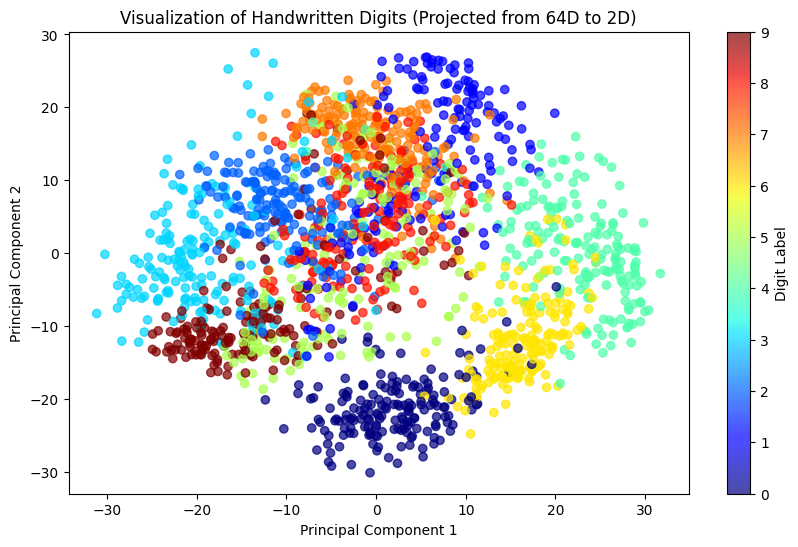

In [14]:
# --- EXPLORATORY DATA ANALYSIS: DIMENSIONALITY REDUCTION ---
# The dataset has 64 features (dimensions). As 64 dimensions cannot be plotted.
# I will use PCA to project the data into 2D space to visualize the clusters.

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='jet', alpha=0.7)
plt.colorbar(scatter, label='Digit Label')
plt.title('Visualization of Handwritten Digits (Projected from 64D to 2D)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

# Analysis: Digits like '0' (Dark Blue) form tight clusters, 
# while digits in the middle (like '5' and '8') show some overlap.

In [15]:
from sklearn.base import BaseEstimator, ClassifierMixin

class MyKNN(BaseEstimator, ClassifierMixin):
    def __init__(self, k=3):
        self.k = k

    def fit(self, X, y):
        """
        Store the training data.
        """
        self.X_train = np.array(X)
        self.y_train = np.array(y)
        return self 

    def predict(self, X):
        """
        Predict for a list of observations.
        """
        X = np.array(X)
        predictions = [self._predict_one(x) for x in X]
        return np.array(predictions)

    def _predict_one(self, x):
        # Applying Euclidean Distance Formula
        distances = [np.sqrt(np.sum((x_train - x) ** 2)) for x_train in self.X_train]
        
        # Getting indices of the k nearest neighbors
        k_indices = np.argsort(distances)[:self.k]
        
        # Getting labels of those neighbors
        k_nearest_labels = [self.y_train[i] for i in k_indices]
        
        # Voting
        most_common = Counter(k_nearest_labels).most_common(1)
        return most_common[0][0]

In [16]:
# Splitting Data 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling Data 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Running systematic evaluation on k values...
k=1: 0.9778
k=3: 0.9694
k=5: 0.9750
k=7: 0.9722
k=9: 0.9722
k=11: 0.9722
k=13: 0.9722
k=15: 0.9667


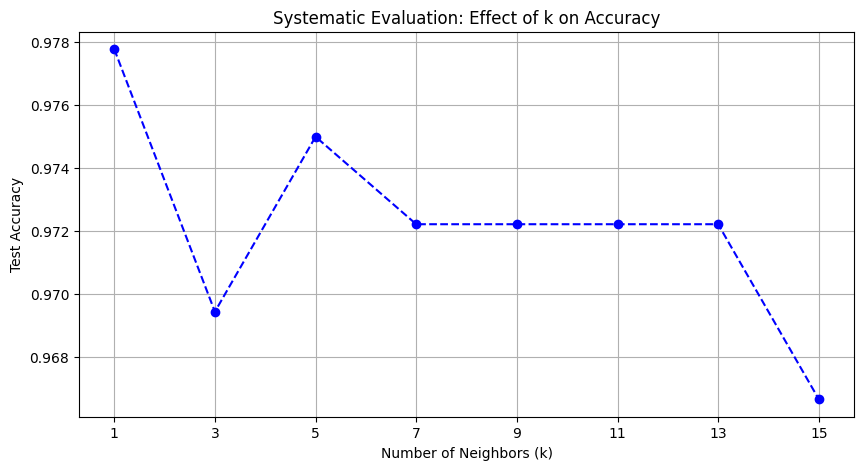


Optimization Complete. Best k value found: 1


In [17]:
#  SYSTEMATIC EVALUATION: TUNING THE HYPERPARAMETER 'k' 
# I will test odd numbers from 1 to 15 to find the best balance
k_values = range(1, 16, 2) 
accuracies = []

print("Running systematic evaluation on k values...")

for k in k_values:
    # I will use a fresh model for each k
    knn_temp = MyKNN(k=k)
    knn_temp.fit(X_train_scaled, y_train)
    pred_temp = knn_temp.predict(X_test_scaled)
    acc_temp = accuracy_score(y_test, pred_temp)
    accuracies.append(acc_temp)
    print(f"k={k}: {acc_temp:.4f}")

# VISUALIZATION: Accuracy vs k
plt.figure(figsize=(10, 5))
plt.plot(k_values, accuracies, marker='o', color='blue', linestyle='dashed')
plt.title('Systematic Evaluation: Effect of k on Accuracy')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Test Accuracy')
plt.grid(True)
plt.xticks(k_values)
plt.show()

# Automatically selecting the best k
best_k = k_values[np.argmax(accuracies)]
print(f"\nOptimization Complete. Best k value found: {best_k}")

In [18]:
from sklearn.model_selection import cross_val_score

#  METHODOLOGY: CROSS-VALIDATION 
# Cross-validation will provide me a more robust estimate of performance than a single split.

print("Running 5-Fold Cross-Validation on Decision Tree...")
# I will use the unscaled data for Decision Trees 
dt_cv_model = DecisionTreeClassifier(random_state=42, max_depth=10)
dt_scores = cross_val_score(dt_cv_model, X, y, cv=5, scoring='accuracy')

print(f"Decision Tree CV Scores: {dt_scores}")
print(f"Decision Tree Average Accuracy: {dt_scores.mean():.4f} (+/- {dt_scores.std() * 2:.4f})")

print("\nRunning 5-Fold Cross-Validation on Custom kNN...")
knn_cv_model = MyKNN(k=best_k)
knn_scores = cross_val_score(knn_cv_model, X, y, cv=5, scoring='accuracy')
print(f"kNN CV Average Accuracy: {knn_scores.mean():.4f}")

Running 5-Fold Cross-Validation on Decision Tree...
Decision Tree CV Scores: [0.79722222 0.71666667 0.80779944 0.83286908 0.78830084]
Decision Tree Average Accuracy: 0.7886 (+/- 0.0779)

Running 5-Fold Cross-Validation on Custom kNN...
kNN CV Average Accuracy: 0.9650


EXPERIMENT 1: My Custom kNN (From Scratch)
My kNN Model (k=1) Performance:
Accuracy: 0.9778
------------------------------

EXPERIMENT 2: Decision Tree (Scikit-Learn)
Decision Tree Performance:
Accuracy: 0.8500
------------------------------

CONCLUSION
The Custom kNN model outperformed the Decision Tree by 0.1278.


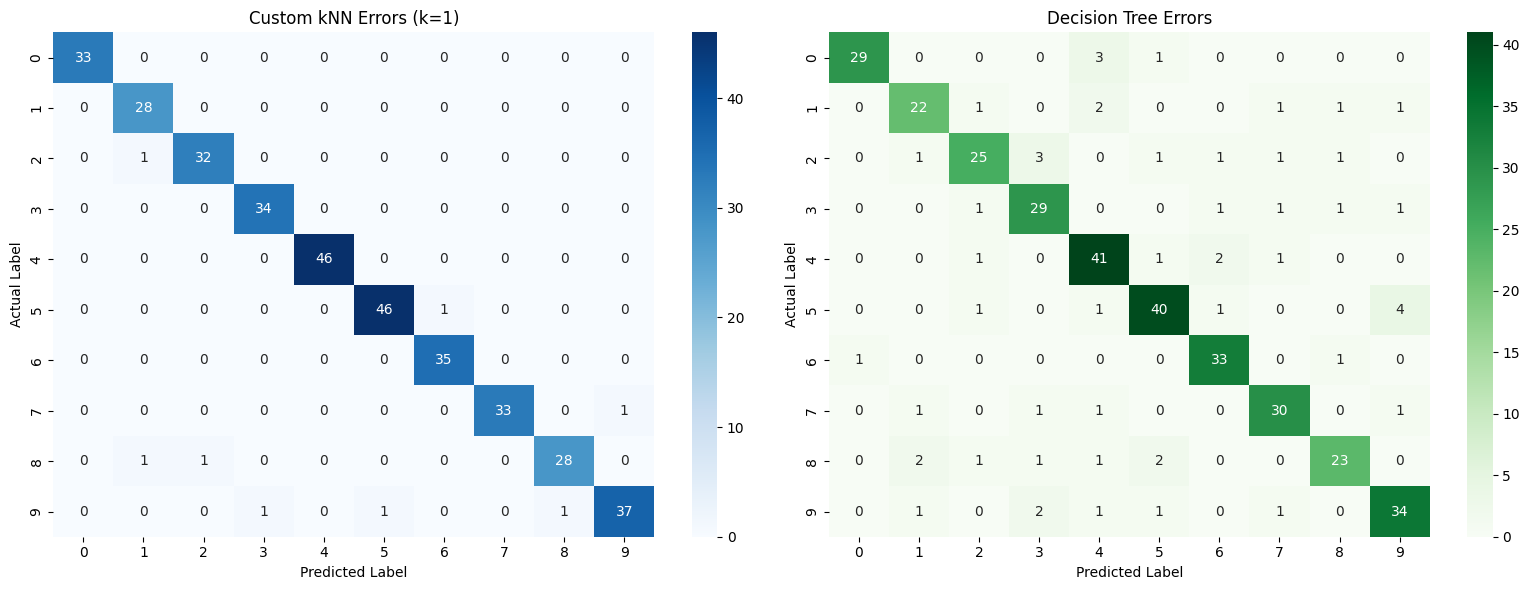

In [19]:
#  FINAL EXPERIMENTS AND RESULTS 

print("="*50)
print("EXPERIMENT 1: My Custom kNN (From Scratch)")
print("="*50)

# 1. Training and Predicting with MyKNN
# I will use the best_k found in the previous tuning step
final_knn = MyKNN(k=best_k)
final_knn.fit(X_train_scaled, y_train)
final_knn_pred = final_knn.predict(X_test_scaled)
final_knn_acc = accuracy_score(y_test, final_knn_pred)

# PRINTING KNN RESULTS IMMEDIATELY
print(f"My kNN Model (k={best_k}) Performance:")
print(f"Accuracy: {final_knn_acc:.4f}")
print("-" * 30)


print("\n" + "="*50)
print("EXPERIMENT 2: Decision Tree (Scikit-Learn)")
print("="*50)

# 2. Training and Predicting with Decision Tree
final_dt = DecisionTreeClassifier(random_state=42, max_depth=10)
final_dt.fit(X_train, y_train)
final_dt_pred = final_dt.predict(X_test)
final_dt_acc = accuracy_score(y_test, final_dt_pred)

# PRINTING DECISION TREE RESULTS IMMEDIATELY
print(f"Decision Tree Performance:")
print(f"Accuracy: {final_dt_acc:.4f}")
print("-" * 30)


#  FINAL COMPARISON AND ERROR VISUALIZATION 
print("\n" + "="*50)
print("CONCLUSION")
print("="*50)
if final_knn_acc > final_dt_acc:
    print(f"The Custom kNN model outperformed the Decision Tree by {final_knn_acc - final_dt_acc:.4f}.")
else:
    print(f"The Decision Tree outperformed the Custom kNN model by {final_dt_acc - final_knn_acc:.4f}.")

# Plotting Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(confusion_matrix(y_test, final_knn_pred), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title(f'Custom kNN Errors (k={best_k})')
axes[0].set_ylabel('Actual Label')
axes[0].set_xlabel('Predicted Label')

sns.heatmap(confusion_matrix(y_test, final_dt_pred), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Decision Tree Errors')
axes[1].set_ylabel('Actual Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()